# Phân tích và dự đoán giá thuê nhà bằng hồi quy Ridge và mô hình rừng ngẫu nhiên

Notebook này dự đoán tiền thuê hằng tháng (`price_vnd`) từ dữ liệu tin đăng NhaTot đã làm sạch và loại các dòng được đánh dấu ngoại lệ trong `is_outlier`. Mô hình sử dụng diện tích, quận/huyện và tình trạng nội thất khi có dữ liệu. Có thể đổi `TARGET` hoặc `FEATURES` nếu mục tiêu phân tích khác.

Cờ ngoại lệ chỉ dùng để lọc dòng, không dùng làm biến dự đoán. Các trường `price_per_m2`, `price_outlier` và `area_outlier` bị loại vì được tính từ biến mục tiêu hoặc thể hiện quyết định làm sạch dữ liệu. Văn bản, URL và thông tin định danh người bán cũng không được sử dụng.

In [ ]:
import csv
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

DATA_PATH = Path('nhatot_cleaned.csv')
TARGET = 'price_vnd'
FEATURES = ['area_m2', 'district', 'furniture_status']

# Đọc file CSV trực tiếp bằng pandas
df = pd.read_csv(DATA_PATH)
print(f'Đã tải {len(df):,} dòng và {df.shape[1]} cột')
display(df.head())

Đã tải 989 dòng và 18 cột


,title,price,area,post_date,address,update_date_text,furniture_status,deposit,description,seller_name,post_url,seller_profile_url,collection_date,price_vnd,area_m2,post_date_clean,district,price_per_m2
0,Phòng trọ 25m2 full nội thất - Ngã Tư Phú Nhuận,6 triệu/tháng,25 m²,2025-07-16,"423/10, Nguyễn Kiệm, , , Tp Hồ Chí Minh",6 ngày trước,NaN,6.000.000 đ/tháng,Ngã tư Phú Nhuận chính chủ:\nTầng 2: Phòng 25m...,Hạnh,https://www.nhatot.com/126165413.htm,https://www.nhatot.com/user/8ea123e82234317b50...,2025-07-22,6000000.0,25.0,2025-07-16,Không xác định,240000.000000
1,Phòng trọ 1tr9 và 2tr QL50 -ĐA PHƯỚC BÌNH CHÁNH,"1,9 triệu/tháng",40 m²,2025-07-15,"dương đình cúc, Xã Tân Kiên, Huyện Bình Chánh,...",1 tuần trước,NaN,NaN,"***Phòng Trọ Bình Chánh***\n->>Từ 1tr9 -2tr ,r...",NGUYỄN KIM VÀNG,https://www.nhatot.com/thue-bat-dong-san-huyen...,https://www.nhatot.com/user/5386d8ccf8afc19851...,2025-07-22,1900000.0,40.0,2025-07-15,Huyện Bình Chánh,47500.000000
2,Phòng trọ cho thuê một đôi vợ chồng.,"1,5 triệu/tháng",12 m²,2025-07-22,"D7/21,KP8, Đường cao tốc TP Hồ Chí Minh – Trun...",9 giờ trước,Nhà trống,500.000 đ/tháng,Phòng trọ cho thuê một đôi vợ chồng\n12m2\nKhô...,thành nguyễn việt,https://www.nhatot.com/thue-bat-dong-san-huyen...,https://www.nhatot.com/user/d75d63d7481cdeea50...,2025-07-22,1500000.0,12.0,2025-07-22,Huyện Bình Chánh,125000.000000
3,CHO THUÊ 1 PHÒNGTRỐNG TRÊN ĐƯỜNG BÀ TRIỆU GẦN ...,"1,2 triệu/tháng",20 m²,2025-06-22,"19, Tổ 23, KP1-10, Đường Bà Triệu, Thị trấn Hó...",1 tháng trước,Nhà trống,600.000 đ/tháng,Mình chính chủ còn 1 phòng trống cần cho thuê....,Nguyễn Thu Hòa,https://www.nhatot.com/thue-bat-dong-san-huyen...,https://www.nhatot.com/user/6ced3fa68833ee1c67...,2025-07-22,1200000.0,20.0,2025-06-22,Huyện Hóc Môn,60000.000000
4,"CHO THUÊ PHÒNG SẠCH SẼ TẠI NHÀ BÈ, GẦN KCN HIỆ...","1,8 triệu/tháng",17 m²,2025-06-24,"Hẻm 489/17/11, Hẻm 489 Nguyễn Văn Tạo, Xã Long...",4 tuần trước,NaN,1.000.000 đ/tháng,"Địa chỉ: Hẻm 489/17/11 Nguyễn Văn Tạo, xã Long...",Văn minh,https://www.nhatot.com/thue-bat-dong-san-huyen...,https://www.nhatot.com/user/492f8ee1da04b4e25b...,2025-07-22,1800000.0,17.0,2025-06-24,Huyện Nhà Bè,105882.352941


,Số giá trị thiếu
price_vnd,0
area_m2,0
district,0
furniture_status,260


,price_vnd
count,9.890000e+02
mean,3.731628e+06
std,1.638299e+06
min,1.000000e+06
25%,2.500000e+06
50%,3.600000e+06
75%,4.800000e+06
max,8.500000e+06


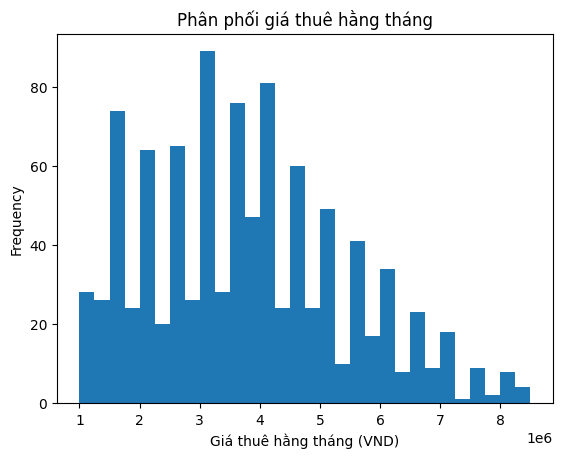

In [ ]:
# Chỉ giữ các cột cần thiết; chuyển biến mục tiêu sang dạng số và bỏ dòng không có giá trị mục tiêu hợp lệ.
required = [TARGET] + FEATURES
missing_columns = [c for c in required if c not in df.columns]
if missing_columns:
    raise KeyError(f'Thiếu các cột cần thiết: {missing_columns}')

model_data = df[required].copy()
model_data[TARGET] = pd.to_numeric(model_data[TARGET], errors='coerce')
model_data = model_data.dropna(subset=[TARGET])
model_data = model_data[model_data[TARGET] > 0]

# Xem chuỗi rỗng là dữ liệu thiếu, sau đó hiển thị số lượng dữ liệu thiếu và phân phối biến mục tiêu.
for col in FEATURES:
    if model_data[col].dtype == 'object':
        model_data[col] = model_data[col].replace(r'^\s*$', pd.NA, regex=True)

display(model_data.isna().sum().rename('Số giá trị thiếu').to_frame())
display(model_data[TARGET].describe().to_frame())
model_data[TARGET].plot(kind='hist', bins=30, title='Phân phối giá thuê hằng tháng')
plt.xlabel('Giá thuê hằng tháng (VND)')
plt.show()

In [ ]:
X = model_data[FEATURES]
y = model_data[TARGET]
numeric_features = X.select_dtypes(include='number').columns.tolist()
categorical_features = [c for c in FEATURES if c not in numeric_features]

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])
preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
# Tinh chỉnh cả hai mô hình trên cùng tập huấn luyện và dùng MAE làm tiêu chí đánh giá.
ridge_pipeline = Pipeline([('preprocess', preprocessor), ('model', Ridge())])
ridge_search = GridSearchCV(
    ridge_pipeline,
    param_grid={'model__alpha': [0.01, 0.1, 1, 10, 100, 1000]},
    scoring='neg_mean_absolute_error', cv=5, n_jobs=-1,
)
ridge_search.fit(X_train, y_train)
ridge_model = ridge_search.best_estimator_
ridge_predictions = ridge_model.predict(X_test)

forest_pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('model', RandomForestRegressor(random_state=42, n_jobs=-1)),
])
forest_search = GridSearchCV(
    forest_pipeline,
    param_grid={
        'model__n_estimators': [200],
        'model__max_depth': [None, 10, 20],
        'model__min_samples_leaf': [1, 3, 5],
    },
    scoring='neg_mean_absolute_error', cv=5, n_jobs=-1,
)
forest_search.fit(X_train, y_train)
forest_model = forest_search.best_estimator_
forest_predictions = forest_model.predict(X_test)

predictions = {'Ridge': ridge_predictions, 'Random Forest': forest_predictions}
baseline_predictions = [y_train.median()] * len(y_test)
def regression_metrics(actual, predicted):
    return {
        'MAE (VND)': mean_absolute_error(actual, predicted),  # Sai số tuyệt đối trung bình
        'RMSE (VND)': mean_squared_error(actual, predicted) ** 0.5,  # Căn bậc hai sai số bình phương trung bình
        'R²': r2_score(actual, predicted),  # Hệ số xác định
    }

all_predictions = {**predictions, 'Mốc dự đoán trung vị': baseline_predictions}
comparison = pd.DataFrame({name: regression_metrics(y_test, pred) for name, pred in all_predictions.items()}).T
comparison.index.name = 'Mô hình'
# Hiển thị bảng đánh giá chung của ba phương pháp.
comparison_display = comparison.rename(columns={
    'MAE (VND)': 'Sai số tuyệt đối trung bình (VND)',
    'RMSE (VND)': 'Căn bậc hai sai số bình phương trung bình (VND)',
    'R²': 'Hệ số xác định R²',
})
display(comparison_display.round({
    'Sai số tuyệt đối trung bình (VND)': 0,
    'Căn bậc hai sai số bình phương trung bình (VND)': 0,
    'Hệ số xác định R²': 3,
}))

best_parameters = pd.DataFrame.from_dict({
    'Ridge': {
        'Tham số điều chuẩn alpha': ridge_search.best_params_['model__alpha'],
        'Số cây': '—',
        'Độ sâu tối đa': '—',
        'Số mẫu tối thiểu mỗi lá': '—',
    },
    'Rừng ngẫu nhiên': {
        'Tham số điều chuẩn alpha': '—',
        'Số cây': forest_search.best_params_['model__n_estimators'],
        'Độ sâu tối đa': forest_search.best_params_['model__max_depth'],
        'Số mẫu tối thiểu mỗi lá': forest_search.best_params_['model__min_samples_leaf'],
    },
}).T
best_parameters.index.name = 'Mô hình'
print('Cấu hình tốt nhất được chọn qua kiểm định chéo:')
display(best_parameters)

,Sai số tuyệt đối trung bình (VND),Căn bậc hai sai số bình phương trung bình (VND),Hệ số xác định R²
Mô hình,,,
Ridge,892766.0,1163944.0,0.546
Random Forest,882344.0,1145154.0,0.561
Mốc dự đoán trung vị,1420303.0,1729992.0,-0.002


Cấu hình tốt nhất được chọn qua kiểm định chéo:


,Tham số điều chuẩn alpha,Số cây,Độ sâu tối đa,Số mẫu tối thiểu mỗi lá
Mô hình,,,,
Ridge,1,—,—,—
Rừng ngẫu nhiên,—,200,10,3


Sai số tuyệt đối trung bình của mốc trung vị: 1,420,303 VND
Mức giảm sai số của Ridge so với mốc cơ sở: 527,537 VND
Mức giảm sai số của mô hình rừng ngẫu nhiên so với mốc cơ sở: 537,959 VND


,Giá thuê thực tế (VND),Dự đoán Ridge (VND),Dự đoán rừng ngẫu nhiên (VND),Sai số Ridge (VND),Sai số rừng ngẫu nhiên (VND)
0,5500000.0,4134416.0,4202700.0,1365584.0,1297300.0
1,2400000.0,2964252.0,3031733.0,-564252.0,-631733.0
2,2000000.0,2032307.0,2131195.0,-32307.0,-131195.0
3,3000000.0,3529201.0,3239691.0,-529201.0,-239691.0
4,4800000.0,4230837.0,4392970.0,569163.0,407030.0
5,2200000.0,2394211.0,2384569.0,-194211.0,-184569.0
6,4600000.0,3326155.0,3799385.0,1273845.0,800615.0
7,5200000.0,4520360.0,4718536.0,679640.0,481464.0
8,1900000.0,4479520.0,4433786.0,-2579520.0,-2533786.0
9,1450000.0,1670403.0,2034192.0,-220403.0,-584192.0


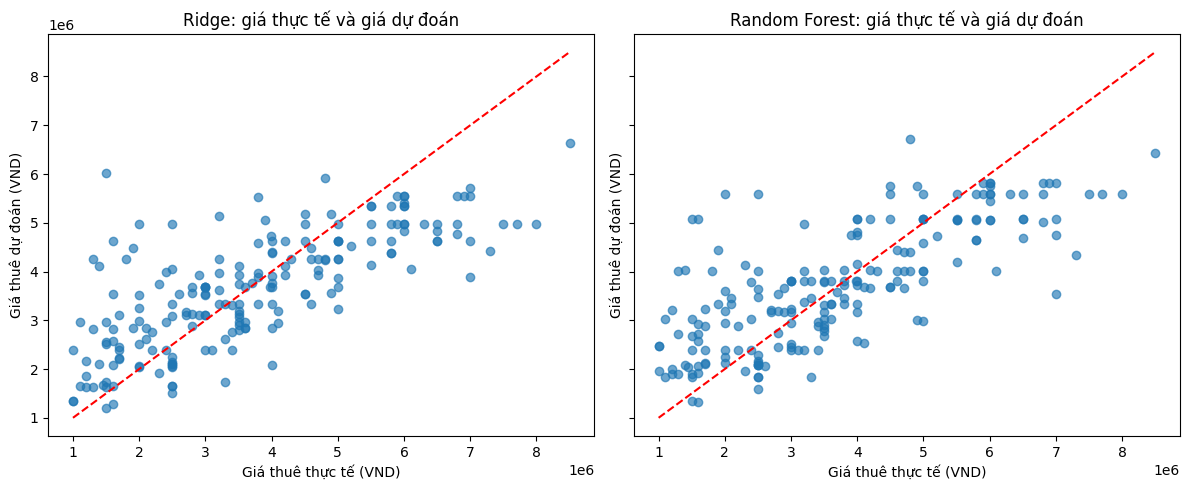

In [ ]:
# So sánh hai mô hình với mốc cơ sở đơn giản: luôn dự đoán trung vị giá thuê của tập huấn luyện.
baseline_predictions = [y_train.median()] * len(y_test)
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
print(f'Sai số tuyệt đối trung bình của mốc trung vị: {baseline_mae:,.0f} VND')
print(f'Mức giảm sai số của Ridge so với mốc cơ sở: {baseline_mae - comparison.loc["Ridge", "MAE (VND)"]:,.0f} VND')
print(f'Mức giảm sai số của mô hình rừng ngẫu nhiên so với mốc cơ sở: {baseline_mae - comparison.loc["Random Forest", "MAE (VND)"]:,.0f} VND')

results = pd.DataFrame({
    'Giá thuê thực tế (VND)': y_test.values,
    'Dự đoán Ridge (VND)': ridge_predictions,
    'Dự đoán rừng ngẫu nhiên (VND)': forest_predictions,
})
results['Sai số Ridge (VND)'] = results['Giá thuê thực tế (VND)'] - results['Dự đoán Ridge (VND)']
results['Sai số rừng ngẫu nhiên (VND)'] = results['Giá thuê thực tế (VND)'] - results['Dự đoán rừng ngẫu nhiên (VND)']
display(results.head(10).round(0))

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, name, pred in zip(axes, predictions, predictions.values()):
    ax.scatter(y_test, pred, alpha=0.65)
    low, high = min(y_test.min(), pred.min()), max(y_test.max(), pred.max())
    ax.plot([low, high], [low, high], 'r--')
    ax.set_title(f'{name}: giá thực tế và giá dự đoán')
    ax.set_xlabel('Giá thuê thực tế (VND)')
    ax.set_ylabel('Giá thuê dự đoán (VND)')
plt.tight_layout()
plt.show()

## Kết luận

Trên tập kiểm tra, Ridge đạt MAE khoảng **892.766 VND**, còn mô hình rừng ngẫu nhiên đạt MAE khoảng **882.344 VND**. Mốc cơ sở luôn dự đoán trung vị có MAE khoảng **1.420.303 VND**.

- Cả hai mô hình đều cải thiện so với mốc cơ sở: Ridge giảm MAE khoảng **527,537 VND**, còn mô hình rừng ngẫu nhiên giảm khoảng **537,959 VND**.
- Mô hình rừng ngẫu nhiên tốt hơn Ridge khoảng **10,433 VND MAE** trên lần trên tập kiểm tra này. Kết quả cho thấy mô hình rừng ngẫu nhiên là lựa chọn nhỉnh hơn trong lần thử này, dù chênh lệch giữa hai mô hình khá nhỏ.
- Các con số phản ánh sai số trên một tập kiểm tra cụ thể; chúng chưa đảm bảo hiệu quả tương tự với tin đăng mới. Ở bài toán này, do giá thuê nhà thường bị ảnh hưởng phức tạp bởi nhiều yếu tố kết hợp (vị trí, diện tích, số phòng, tiện ích...) tạo ra các mối quan hệ phi tuyến tính, nên mô hình tuyến tính có bồi thêm hàm phạt như Ridge không thể bắt kịp quy luật này là hoàn toàn hợp lý.
- Đây là mẫu dữ liệu nhỏ tại một thời điểm nên kết quả có thể không áp dụng cho thời điểm hoặc khu vực khác. Giá thuê còn có thể phụ thuộc vào loại phòng, vị trí cụ thể, tiện nghi và chất lượng tin đăng. Mô hình thể hiện mối liên hệ phục vụ dự đoán, không chứng minh quan hệ nhân quả.